# Estrés inverso: sensibilidad de fondeo a DTF

## Resumen

Con las hipótesis de deuda y presupuesto indicadas, el umbral es +2 puntos porcentuales de DTF en un año. En 28 de 201 meses de la ventana observada se excedió; las ventanas se solapan y no son una probabilidad futura.

## Contexto y método

Para una deuda hipotética de COP 100.000 millones que se reprecia totalmente en un año, calculamos qué subida de DTF agotaría un presupuesto incremental hipotético de COP 2.000 millones. La DTF mensual del Atlas deriva de Banco de la República: [metodología DTF](https://www.banrep.gov.co/es/cual-metodologia-calculo-dtf-y-normativa-relacionada). Usamos comparaciones interanuales de meses completos desde 2010 hasta septiembre de 2026. El umbral es impuesto, no apetito aprobado, ni probabilidad de incumplimiento.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Abrir el notebook desde un clon del repositorio.')
plt.rcParams.update({'figure.figsize': (9, 4.4), 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})


## Datos

Insumo versionado en el repositorio: `04-quant-strategy-and-products/treasury-and-alm/sensibilidad-fondeo-dtf/data/dtf_monthly_derived.csv`. SHA-256: `56e4e436cd7add0aac50dd8e1c29007fa173ed8e07e4b484633d19faa33c79ec`. No se requieren credenciales. La fuente primaria y los procesos de extracción se documentan en el README del companion de origen.

In [2]:
DATA = ROOT / '04-quant-strategy-and-products/treasury-and-alm/sensibilidad-fondeo-dtf/data/dtf_monthly_derived.csv'
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == '56e4e436cd7add0aac50dd8e1c29007fa173ed8e07e4b484633d19faa33c79ec'
print('Archivo y huella verificados:', DATA.name)

Archivo y huella verificados: dtf_monthly_derived.csv


## Resultados

La tabla de entrada se valida antes del cálculo; la figura representa los resultados del corte indicado.

In [3]:
df = pd.read_csv(DATA)
df['date'] = pd.to_datetime(df.mes + '-01')
assert not df.date.duplicated().any()
df = df.set_index('date').sort_index().asfreq('MS')
df['cambio_pp_12m'] = df.dtf_promedio - df.dtf_promedio.shift(12)
x = df.loc['2010-01':'2026-09'].dropna(subset=['cambio_pp_12m']).copy()
notional = 100_000  # COP millones
budget = 2_000  # COP millones al año, supuesto
threshold_pp = budget / notional * 100
x['costo_incremental_millones'] = notional*x.cambio_pp_12m/100
print(f'Umbral inverso ilustrativo: +{threshold_pp:.2f} puntos porcentuales en un año')
print(f'Meses que superan el umbral: {(x.cambio_pp_12m > threshold_pp).sum()} de {len(x)} observaciones; máximo: {x.cambio_pp_12m.max():.2f} pp')


Umbral inverso ilustrativo: +2.00 puntos porcentuales en un año
Meses que superan el umbral: 28 de 201 observaciones; máximo: 10.46 pp


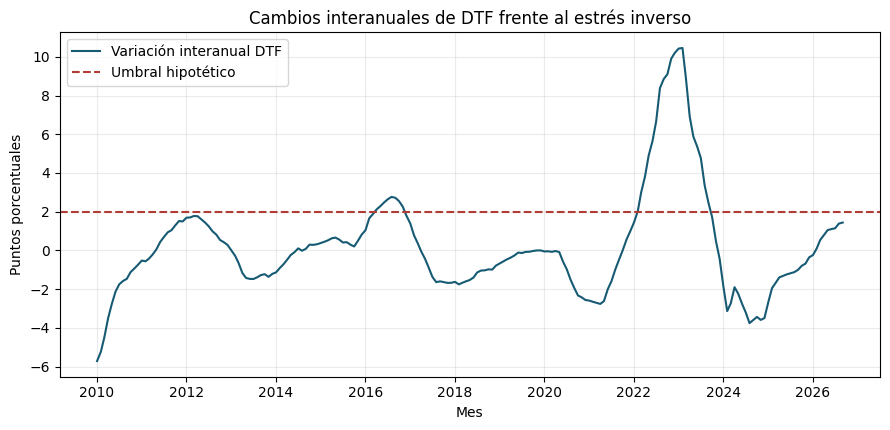

In [4]:
fig, ax = plt.subplots(); ax.plot(x.index, x.cambio_pp_12m, color='#165a73', label='Variación interanual DTF'); ax.axhline(threshold_pp, color='#b13b35', linestyle='--', label='Umbral hipotético'); ax.set(title='Cambios interanuales de DTF frente al estrés inverso', ylabel='Puntos porcentuales', xlabel='Mes'); ax.legend(); fig.tight_layout(); plt.show()

## Interpretación y límites

El conteo histórico es descriptivo y contiene ventanas solapadas; no estima una probabilidad futura. La sensibilidad omite plazos, margen de fondeo, repricing parcial y opciones; requiere contratos y flujos propios para uso institucional.

## Sensibilidad a presupuesto y proporción de deuda que reprecia

Para presupuesto anual B, deuda N y proporción repricing f, el umbral es `100 × B / (N × f)` puntos porcentuales. Se comparan hipótesis explícitas, sin suponer que la DTF representa el costo de todos los contratos. En cada escenario se usa estrictamente `cambio > umbral`; igualdad implica agotar exactamente el presupuesto.

In [5]:
assert df.dtf_promedio.dropna().between(0,100).all(), 'DTF fuera de rango porcentual'
assert df.index.is_unique and x.cambio_pp_12m.notna().all()
scenarios = []
for frac in [0.5,1.0]:
    for budget in [1000,2000,3000]:
        threshold = 100*budget/(notional*frac)
        count = int(x.cambio_pp_12m.gt(threshold).sum())
        scenarios.append({'repricing_fraccion':frac,'presupuesto_COP_millones':budget,'umbral_pp':threshold,'meses_superan':count,'meses_evaluados':len(x),'frecuencia_descriptiva':count/len(x)})
scenario_table=pd.DataFrame(scenarios)
assert scenario_table.meses_superan.between(0,len(x)).all()
scenario_table.round(3)

,repricing_fraccion,presupuesto_COP_millones,umbral_pp,meses_superan,meses_evaluados,frecuencia_descriptiva
0,0.5,1000,2.0,28,201,0.139
1,0.5,2000,4.0,15,201,0.075
2,0.5,3000,6.0,10,201,0.050
3,1.0,1000,1.0,51,201,0.254
4,1.0,2000,2.0,28,201,0.139
5,1.0,3000,3.0,18,201,0.090


La frecuencia no es una probabilidad de pérdida futura: utiliza ventanas interanuales solapadas y un solo corte histórico. No incluye vencimientos, cobertura, tasas contractuales ni refinanciación.

## Literatura y alcance del estrés inverso

Los [principios de stress testing del FSB/BCBS (2018)](https://www.fsb.org/2018/10/stress-testing-principles/) sitúan escenarios y gobierno en el marco de riesgos. Aquí se resuelve un **umbral de costo hipotético** con DTF, no un escenario de inviabilidad de una entidad ni un ejercicio regulatorio. Comparar calendarios reduce el solapamiento; no elimina dependencia temporal ni selección histórica.

## Variante: ventanas anuales sin solapamiento

Se conserva un solo cambio diciembre a diciembre por año completo. La proporción de años que supera +2 pp es una **frecuencia descriptiva del periodo**, no una probabilidad futura; el tamaño de muestra pequeño y las condiciones cambiantes limitan su uso. No se corrige por selección de fecha ni se atribuye independencia.

In [6]:
annual=x.loc[x.index.month==12, ['cambio_pp_12m']].copy()
annual['supera_umbral']=annual.cambio_pp_12m.gt(threshold_pp)
n_anos=len(annual); eventos=int(annual.supera_umbral.sum())
assert n_anos>0 and not annual.index.year.duplicated().any()
print('Años diciembre-diciembre:',n_anos,'| superaciones:',eventos,'| proporción histórica:',round(eventos/n_anos,3))
print('Periodo:',annual.index.min().date(),'a',annual.index.max().date(),'| máximo pp:',round(annual.cambio_pp_12m.max(),2))
annual.tail(8).round(2)

Años diciembre-diciembre: 16 | superaciones: 1 | proporción histórica: 0.062
Periodo: 2010-12-01 a 2025-12-01 | máximo pp: 10.21


,cambio_pp_12m,supera_umbral
date,,
2018-12-01,-0.78,False
2019-12-01,0.00,False
2020-12-01,-2.56,False
2021-12-01,0.98,False
2022-12-01,10.21,True
2023-12-01,-0.43,False
2024-12-01,-3.49,False
2025-12-01,-0.36,False
